# I. DADOS


## Download dos dados


In [ ]:
import io
import time
import zipfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import arff
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, train_test_split)
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)

pasta_projeto = Path.cwd()
if pasta_projeto.name != "02-metodos-ML-II":
    pasta_projeto = pasta_projeto / "02-metodos-ML-II"

pasta_dados = pasta_projeto / "dados"
pasta_dados.mkdir(exist_ok=True)

arquivo_cdc = pasta_dados / "cdc.csv"
arquivo_wine = pasta_dados / "WineQT.csv"

if not arquivo_cdc.exists():
    print("Baixando cdc.csv...")

    with urlopen("https://openml.org/data/v1/download/22124404/cdc_diabetes.arff") as resposta:
        dados_baixados = resposta.read()

    texto_cdc = dados_baixados.decode("utf-8")
    arquivo_em_memoria = io.StringIO(texto_cdc)
    registros, informacoes = arff.loadarff(arquivo_em_memoria)

    cdc_download = pd.DataFrame(registros)
    classes_cdc = cdc_download["Diabetes_binary"].str.decode("utf-8")
    cdc_download["Diabetes_binary"] = classes_cdc.astype(int)
    cdc_download.to_csv(arquivo_cdc, index=False)

print("cdc.csv disponível!")

if not arquivo_wine.exists():
    print("Baixando WineQT.csv...")

    with urlopen("https://www.kaggle.com/api/v1/datasets/download/yasserh/wine-quality-dataset") as resposta:
        dados_baixados = resposta.read()

    arquivo_em_memoria = io.BytesIO(dados_baixados)
    with zipfile.ZipFile(arquivo_em_memoria) as pacote:
        with pacote.open("WineQT.csv") as arquivo:
            wine_baixado = pd.read_csv(arquivo)
    wine_baixado.to_csv(arquivo_wine, index=False)

print("WineQT.csv disponível!")

cdc.csv disponível!
WineQT.csv disponível!


## CDC

Esse dataset tem informações de saúde relatadas por participantes de uma pesquisa, com e sem diabetes. Tem ifnormações sobre o estilo de vida (se a pessoa fuma, faz exercício físico), dados demográficos (idade e sexo), dados socioeconomicos (renda e grau de educaçao) e tbm indicadores de saúde relatados (pressão alta, colestoresol alto, histórico de doença cardíaca ou infarto e IMC) a classe é 0 para ausência de diabetes e 1 para pré-diabetes ou diabetes.

O dataset não possui valores nulos ou infinitos e os atributos de entrada já estão em formato numérico. Por isso, não foi necessário remover linhas ou colunas por valores ausentes, preencher esses valores ou aplicar one-hot encoding. Os registros duplicados foram removidos antes da divisão entre treino e teste.

In [ ]:
cdc = pd.read_csv(arquivo_cdc)
quantidade_original_cdc = len(cdc)
duplicados_cdc = int(cdc.duplicated().sum())
cdc = cdc.drop_duplicates().reset_index(drop=True)

print(f"CDC: {quantidade_original_cdc} registros originais, {duplicados_cdc} duplicados removidos e {len(cdc)} registros únicos.")
display(cdc.head())

print("Resumo estatístico do CDC:")
resumo_cdc = cdc.describe()
resumo_cdc.loc["var"] = cdc.var(numeric_only=True)
display(resumo_cdc.round(3))
print("Quantidade de amostras por classe:")
display(cdc["Diabetes_binary"].value_counts().rename("quantidade"))

X_cdc = cdc.drop(columns=["Diabetes_binary"])
y_cdc = cdc["Diabetes_binary"]
X_cdc_train, X_cdc_test, y_cdc_train, y_cdc_test = train_test_split(
    X_cdc, y_cdc, test_size=0.2, random_state=SEED, stratify=y_cdc
)

print("Treino:", X_cdc_train.shape, "Teste:", X_cdc_test.shape)
print(f"Acurácia ao prever sempre 0: {(y_cdc_test == 0).mean():.2%}")
print(f"Acurácia ao prever sempre 1: {(y_cdc_test == 1).mean():.2%}")

CDC: 253680 registros originais, 24206 duplicados removidos e 229474 registros únicos.


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0,0
1,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0,0
2,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0,0
3,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0,0
4,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0,0


Resumo estatístico do CDC:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
count,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,...,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000
mean,0.454,0.442,0.959,28.688,0.466,0.045,0.103,0.733,0.613,0.795,...,0.093,2.602,3.510,4.681,0.186,0.439,8.085,4.980,5.889,0.153
std,0.498,0.497,0.197,6.789,0.499,0.207,0.304,0.442,0.487,0.404,...,0.290,1.065,7.718,9.051,0.389,0.496,3.094,0.993,2.093,0.360
min,0.000,0.000,0.000,12.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,1.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,0.000
25%,0.000,0.000,1.000,24.000,0.000,0.000,0.000,0.000,0.000,1.000,...,0.000,2.000,0.000,0.000,0.000,0.000,6.000,4.000,4.000,0.000
50%,0.000,0.000,1.000,27.000,0.000,0.000,0.000,1.000,1.000,1.000,...,0.000,3.000,0.000,0.000,0.000,0.000,8.000,5.000,6.000,0.000
75%,1.000,1.000,1.000,32.000,1.000,0.000,0.000,1.000,1.000,1.000,...,0.000,3.000,2.000,4.000,0.000,1.000,10.000,6.000,8.000,0.000
max,1.000,1.000,1.000,98.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,5.000,30.000,30.000,1.000,1.000,13.000,6.000,8.000,1.000
var,0.248,0.247,0.039,46.093,0.249,0.043,0.093,0.196,0.237,0.163,...,0.084,1.134,59.562,81.918,0.151,0.246,9.576,0.986,4.380,0.130


Quantidade de amostras por classe:


Diabetes_binary
0    194377
1     35097
Name: quantidade, dtype: int64

Treino: (183579, 21) Teste: (45895, 21)
Acurácia ao prever sempre 0: 84.71%
Acurácia ao prever sempre 1: 15.29%


## Wine Quality

O dataset classifica a qualdidade do vinho com notas de 3 a 8 de acordo com as medidas de acidez, acuarm ph, alcool entre outras carcateristicas químicas.

Nota: Foi feita uma nova classificação com base na qualidade pois algumas notas de 3 a 8 tinham poucas amostras e ficava esparso demais. Algo comum para esse dataset na literatura é classificar em novas 3 classes. As novas clases são: 

- Ruim: nota menor ou igual a 4. 
- Médio: notas 5 e 6. 
- Bom: nota maior ou igual a 7.

O dataset não possui valores nulos ou infinitos e os atributos de entrada já estão em formato numérico. Por isso, não foi necessário remover linhas ou colunas por valores ausentes, preencher esses valores ou aplicar one-hot encoding. Os registros duplicados foram removidos antes da divisão entre treino e teste.

In [ ]:
def classes(nota):

    if nota <= 4:
        return "Ruim"
    
    elif nota <= 6:
        return "Médio"
    
    return "Bom"


wine = pd.read_csv(arquivo_wine).drop(columns=["Id"])
quantidade_original_wine = len(wine)
duplicados_wine = int(wine.duplicated().sum())
wine = wine.drop_duplicates().reset_index(drop=True)
wine["classe"] = wine["quality"].apply(classes)

print(f"Wine: {quantidade_original_wine} registros originais, {duplicados_wine} duplicados removidos e {len(wine)} registros únicos.")
display(wine.head())

print("Resumo estatístico do Wine:")
resumo_wine = wine.describe()
resumo_wine.loc["var"] = wine.var(numeric_only=True)
display(resumo_wine.round(3))
print("Quantidade de amostras por classe:")
display(wine["classe"].value_counts().rename("quantidade"))

X_wine = wine.drop(columns=["quality", "classe"])
y_wine = wine["classe"]
X_wine_train, X_wine_test, y_wine_train, y_wine_test = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=SEED, stratify=y_wine
)

print("Treino:", X_wine_train.shape, "Teste:", X_wine_test.shape)
for classe in ["Ruim", "Médio", "Bom"]:
    print(f"Acurácia ao prever sempre {classe}: {(y_wine_test == classe).mean():.2%}")

Wine: 1143 registros originais, 125 duplicados removidos e 1018 registros únicos.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,classe
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Médio
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Médio
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Médio
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Médio
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,Médio


Resumo estatístico do Wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000
mean,8.289,0.534,0.269,2.524,0.087,15.649,46.326,0.997,3.312,0.657,10.452,5.641
std,1.741,0.183,0.196,1.315,0.049,10.177,33.124,0.002,0.158,0.168,1.095,0.812
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000
25%,7.100,0.390,0.090,1.900,0.070,7.000,21.000,0.996,3.210,0.550,9.500,5.000
50%,7.900,0.520,0.250,2.200,0.079,13.000,38.000,0.997,3.310,0.620,10.200,6.000
75%,9.100,0.645,0.420,2.600,0.090,21.000,62.000,0.998,3.400,0.720,11.200,6.000
max,15.900,1.580,1.000,15.500,0.611,68.000,289.000,1.004,4.010,2.000,14.900,8.000
var,3.032,0.034,0.039,1.729,0.002,103.562,1097.168,0.000,0.025,0.028,1.199,0.659


Quantidade de amostras por classe:


classe
Médio    842
Bom      137
Ruim      39
Name: quantidade, dtype: int64

Treino: (814, 11) Teste: (204, 11)
Acurácia ao prever sempre Ruim: 3.92%
Acurácia ao prever sempre Médio: 82.84%
Acurácia ao prever sempre Bom: 13.24%


## Validação cruzada

A validação cruzada é feita somente no treino. Como no projeto anterior, o CDC usa uma amostra estratificada de 5.000 exemplos durante a busca dos hiperparâmetros e depois o melhor modelo é treinado novamente usando todo o treino. No Wine é usado todo o conjunto de treino durante a busca.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# O CDC usa uma amostra estratificada na busca, como no projeto anterior.
X_cdc_busca, _, y_cdc_busca, _ = train_test_split(
    X_cdc_train, y_cdc_train, train_size=5000,
    stratify=y_cdc_train, random_state=SEED
)

# O Wine usa todo o treino na busca.
dados_busca = {
    "CDC": (X_cdc_busca, y_cdc_busca),
    "Wine": (X_wine_train, y_wine_train),
}

dados = {
    "CDC": (X_cdc_train, y_cdc_train, X_cdc_test, y_cdc_test),
    "Wine": (X_wine_train, y_wine_train, X_wine_test, y_wine_test),
}

# II. ÁRVORE DE DECISÃO

## A. Sobre o método

A árvore de decisão separa os dados fazendo perguntas/condicionais sobre os atributos, em que cada nó escolhe um atributo e um valor para dividir os exemplos. O Gini mede o quanto as classes estão misturadas e a entropia mede a incerteza da divisão, nos dois casos a árvore procura a divisão que deixa os grupos mais puros. Quando um exemplo chega em uma folha, a classe mais frequente naquela folha é usada como resposta.

A árvore é considerada uma caixa branca porque é possível visualizar as divisões e acompanhar o caminho feito até a resposta, sabendo exatmente quais foram as decisões que classificaram o exmeplo naquela classe, sendo possível mostrar inclusive o desenho gráfico. Árvores muito profundas podem criar regras muito específicas para cada exemplo e decoram os dados de treino. Parâmetros como `max_depth`, `min_samples_split` e `min_samples_leaf` ajudam a controlar isso. A árvore também é instável porque uma pequena mudança nos dados pode mudar fazer com que uma regra de comparação/divisão não se aplique mais.

## B. Implementação


In [ ]:
grades_arvore = {
    "CDC": {
        "criterion": ["gini", "entropy"],
        "max_depth": [3, 5, 8, 12, None],
        "min_samples_leaf": [1, 5, 20, 50],
    },
    "Wine": {
        "criterion": ["gini", "entropy"],
        "max_depth": [2, 3, 5, 8, None],
        "min_samples_leaf": [1, 2, 5, 10],
    },
}

buscas_arvore = {}
arvores = {}

for nome in ["CDC", "Wine"]:
    X_treino = dados[nome][0]
    y_treino = dados[nome][1]
    
    X_busca = dados_busca[nome][0]
    y_busca = dados_busca[nome][1]

    print(f"{nome}: busca em {len(y_busca)} exemplos. Ajuste final em {len(y_treino)}.")
    print()

    busca = GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        grades_arvore[nome], scoring="f1_macro", cv=cv,
        error_score="raise"
    )

    busca.fit(X_busca, y_busca)
    busca.best_estimator_.fit(X_treino, y_treino)

    buscas_arvore[nome] = busca
    arvores[nome] = busca.best_estimator_

    print("Melhores parâmetros:", busca.best_params_)
    print(f"F1 macro médio na validação: {busca.best_score_:.4f}")
    print()

CDC: busca em 5000 exemplos. Ajuste final em 183579.

Melhores parâmetros: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 1}
F1 macro médio na validação: 0.5923

Wine: busca em 814 exemplos. Ajuste final em 814.

Melhores parâmetros: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 2}
F1 macro médio na validação: 0.4995



## C. Experimento


,modelo,dataset,conjunto,acurácia,precisão macro,revocação macro,F1 macro
0,Árvore de decisão,CDC,treino,0.8526,0.7205,0.5588,0.5690
1,Árvore de decisão,CDC,teste,0.8520,0.7152,0.5582,0.5681
2,Árvore de decisão,Wine,treino,0.9533,0.9032,0.8225,0.8539
3,Árvore de decisão,Wine,teste,0.7745,0.4616,0.4343,0.4446


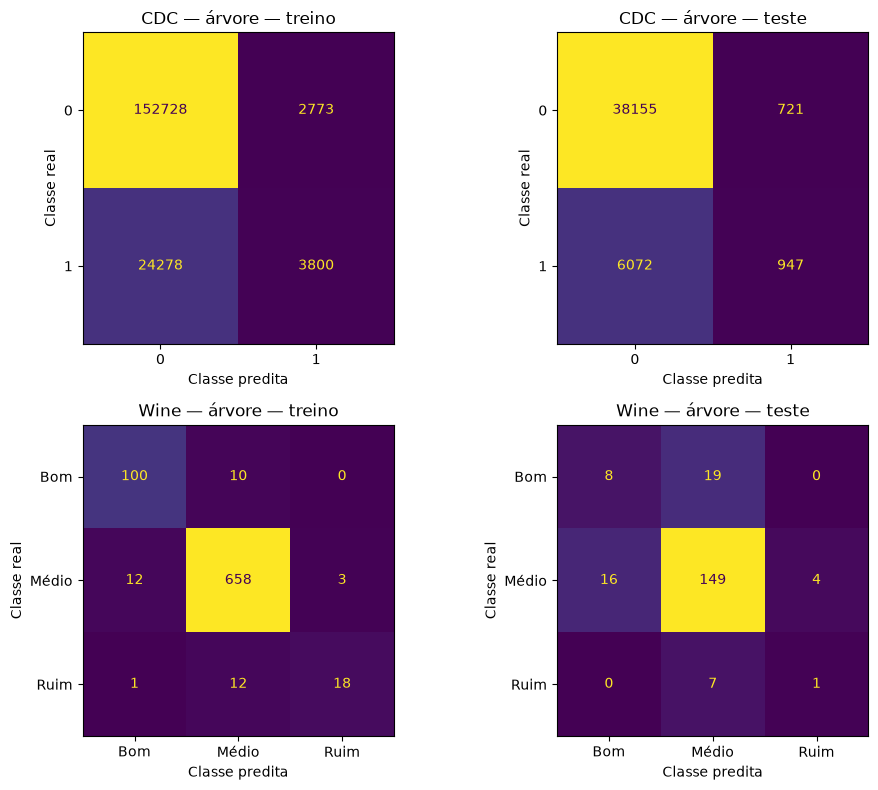

In [ ]:
resultados_arvore = []
predicoes_arvore = {}

for nome in ["CDC", "Wine"]:
    modelo = arvores[nome]

    for conjunto in ["treino", "teste"]:

        if conjunto == "treino":
            X_atual = dados[nome][0]
            y_atual = dados[nome][1]
            
        else:
            X_atual = dados[nome][2]
            y_atual = dados[nome][3]

        y_pred = modelo.predict(X_atual)
        precisao, revocacao, f1, suporte = precision_recall_fscore_support(
            y_atual, y_pred, average="macro", zero_division=0
        )
        resultados_arvore.append({
            "modelo": "Árvore de decisão",
            "dataset": nome,
            "conjunto": conjunto,
            "acurácia": accuracy_score(y_atual, y_pred),
            "precisão macro": precisao,
            "revocação macro": revocacao,
            "F1 macro": f1,
        })
        predicoes_arvore[(nome, conjunto)] = y_pred

resultados_arvore = pd.DataFrame(resultados_arvore)
display(resultados_arvore.round(4))
print()

fig, eixos = plt.subplots(2, 2, figsize=(10, 8), squeeze=False)

for linha, nome in enumerate(["CDC", "Wine"]):
    modelo = arvores[nome]
    labels = modelo.classes_

    for coluna, conjunto in enumerate(["treino", "teste"]):
        if conjunto == "treino":
            y_real = dados[nome][1]
        else:
            y_real = dados[nome][3]

        eixo = eixos[linha, coluna]
        y_pred = predicoes_arvore[(nome, conjunto)]
        ConfusionMatrixDisplay.from_predictions(
            y_real, y_pred, labels=labels, ax=eixo, colorbar=False
        )
        eixo.set_title(f"{nome} — árvore — {conjunto}")
        eixo.set_xlabel("Classe predita")
        eixo.set_ylabel("Classe real")

fig.tight_layout()
plt.show()

### Discussão dos resultados

No CDC, a árvore teve acurácia de 0,8526 e F1 macro de 0,5690 no treino. No teste, a acurácia foi de 0,8520 e o F1 macro foi de 0,5681. Como os resultados ficaram muito próximos no treino e no teste, não aparenta overfiting. A acurácia ficou bem maior que o F1 macro, reforçanedo que somente a acurácia não serve, pois se baseia muito na classe majoritária. Os melhores parâmetros foram critério Gini, profundidade 8 e uma amostra mínima por folha.

No Wine, a acurácia caiu de 0,9533 no treino para 0,7745 no teste e o F1 macro caiu de 0,8539 para 0,4446. Essa diferença aponta muito fortemente para overfiting. Os melhores parâmetros foram entropia, profundidade 8 e duas amostras por folha.


# III. FLORESTA ALEATÓRIA

## A. Sobre o método

A floresta aleatória treina várias árvores usando amostras diferentes dos dados e podendo usar somente um subconjunto das features para escolher as decisões dos níveis. Na previsão final, cada árvore treinada roda a sua classificação e dá um voto. A classe com mais votos é escolhida como classificação final. A vantagm dessa estratégia é que, ao usar uma árvore sozinha, essa uma pode ficar muito instável em relação às mudanças dos atributos e overfiting. A floresta diminui esse problema porque junta o resultado de várias árvores diferentes, que podem ter usado atributos diferentes.

## B. Implementação


In [ ]:
distribuicoes_floresta = {
    "CDC": {
        "n_estimators": [100, 200, 400],
        "max_depth": [5, 10, 20, None],
        "max_features": ["sqrt", 0.5, None],
        "min_samples_leaf": [1, 2, 5, 10, 20],
    },
    "Wine": {
        "n_estimators": [100, 200, 400],
        "max_depth": [3, 5, 10, None],
        "max_features": ["sqrt", 0.5, None],
        "min_samples_leaf": [1, 2, 5, 10],
    },
}

buscas_floresta = {}
florestas = {}
tempos_floresta = {}

for nome in ["CDC", "Wine"]:

    X_treino = dados[nome][0]
    y_treino = dados[nome][1]

    X_busca = dados_busca[nome][0]
    y_busca = dados_busca[nome][1]
    
    print(f"{nome}: busca em {len(y_busca)} exemplos. Ajuste final em {len(y_treino)}.")
    print()

    busca = RandomizedSearchCV(
        RandomForestClassifier(
            random_state=SEED
        ),
        distribuicoes_floresta[nome], n_iter=20,
        scoring="f1_macro", cv=cv,
        random_state=SEED,
        error_score="raise"
    )

    busca.fit(X_busca, y_busca)

    inicio = time.perf_counter()
    busca.best_estimator_.fit(X_treino, y_treino)
    tempos_floresta[nome] = time.perf_counter() - inicio

    buscas_floresta[nome] = busca
    florestas[nome] = busca.best_estimator_

    print("Melhores parâmetros:", busca.best_params_)
    print(f"F1 macro médio na validação: {busca.best_score_:.4f}")
    print(f"Tempo do ajuste final: {tempos_floresta[nome]:.2f} s")
    print()

CDC: busca em 5000 exemplos. Ajuste final em 183579.

Melhores parâmetros: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 10}
F1 macro médio na validação: 0.5772
Tempo do ajuste final: 16.87 s

Wine: busca em 814 exemplos. Ajuste final em 814.

Melhores parâmetros: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 10}
F1 macro médio na validação: 0.4689
Tempo do ajuste final: 0.49 s



## C. Experimento


,modelo,dataset,conjunto,acurácia,precisão macro,revocação macro,F1 macro
0,Floresta aleatória,CDC,treino,0.8581,0.7640,0.5670,0.5815
1,Floresta aleatória,CDC,teste,0.8548,0.7391,0.5596,0.5702
2,Floresta aleatória,Wine,treino,0.9754,0.9904,0.8544,0.9090
3,Floresta aleatória,Wine,teste,0.8627,0.5276,0.4716,0.4889


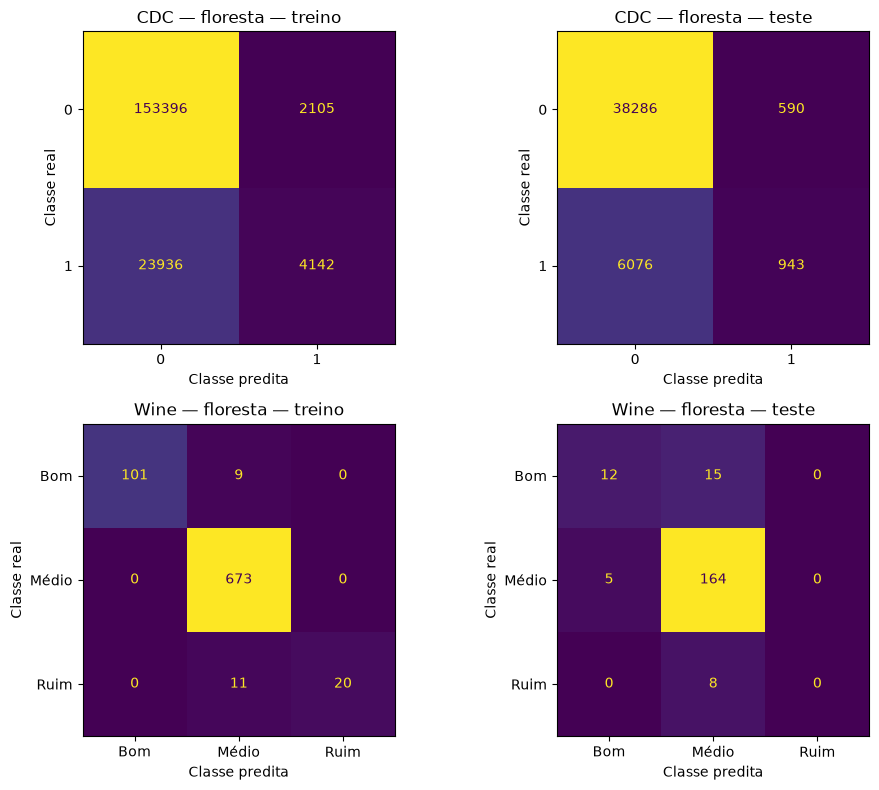

,dataset,n_estimators,F1 macro treino,F1 macro teste
0,CDC,10,0.5874,0.5764
1,CDC,25,0.5848,0.5730
2,CDC,50,0.5828,0.5713
3,CDC,100,0.5815,0.5702
4,CDC,200,0.5817,0.5690
5,CDC,300,0.5811,0.5687
6,CDC,500,0.5820,0.5690
7,Wine,10,0.8833,0.4954
8,Wine,25,0.8882,0.4889
9,Wine,50,0.9210,0.4594


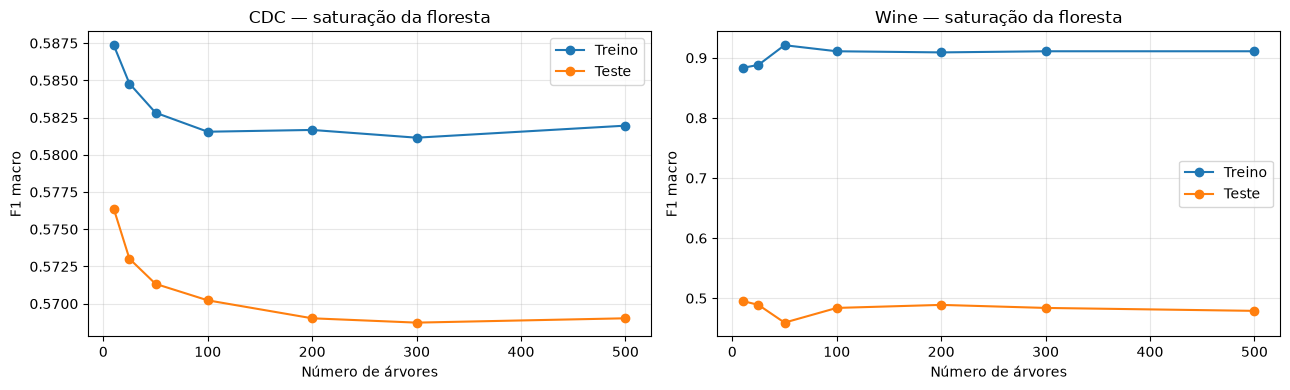

In [ ]:
resultados_floresta = []
predicoes_floresta = {}

for nome in ["CDC", "Wine"]:
    modelo = florestas[nome]

    for conjunto in ["treino", "teste"]:

        if conjunto == "treino":
            X_atual = dados[nome][0]
            y_atual = dados[nome][1]

        else:
            X_atual = dados[nome][2]
            y_atual = dados[nome][3]

        y_pred = modelo.predict(X_atual)
        precisao, revocacao, f1, suporte = precision_recall_fscore_support(
            y_atual, y_pred, average="macro", zero_division=0
        )
        resultados_floresta.append({
            "modelo": "Floresta aleatória",
            "dataset": nome,
            "conjunto": conjunto,
            "acurácia": accuracy_score(y_atual, y_pred),
            "precisão macro": precisao,
            "revocação macro": revocacao,
            "F1 macro": f1,
        })
        predicoes_floresta[(nome, conjunto)] = y_pred

resultados_floresta = pd.DataFrame(resultados_floresta)
display(resultados_floresta.round(4))
print()

fig, eixos = plt.subplots(2, 2, figsize=(10, 8), squeeze=False)

for linha, nome in enumerate(["CDC", "Wine"]):
    modelo = florestas[nome]
    labels = modelo.classes_

    for coluna, conjunto in enumerate(["treino", "teste"]):

        if conjunto == "treino":
            y_real = dados[nome][1]

        else:
            y_real = dados[nome][3]

        eixo = eixos[linha, coluna]
        y_pred = predicoes_floresta[(nome, conjunto)]
        ConfusionMatrixDisplay.from_predictions(
            y_real, y_pred, labels=labels, ax=eixo, colorbar=False
        )
        
        eixo.set_title(f"{nome} — floresta — {conjunto}")
        eixo.set_xlabel("Classe predita")
        eixo.set_ylabel("Classe real")

fig.tight_layout()
plt.show()

quantidades_arvores = [10, 25, 50, 100, 200, 300, 500]
resultados_saturacao = []

for nome in ["CDC", "Wine"]:
    X_treino = dados[nome][0]
    y_treino = dados[nome][1]
    X_teste = dados[nome][2]
    y_teste = dados[nome][3]
    melhor_modelo = florestas[nome]
    parametros = melhor_modelo.get_params()

    for quantidade in quantidades_arvores:
        modelo = RandomForestClassifier(
            n_estimators=quantidade,
            max_depth=parametros["max_depth"],
            max_features=parametros["max_features"],
            min_samples_leaf=parametros["min_samples_leaf"],
            random_state=SEED
        )
        modelo.fit(X_treino, y_treino)

        predicao_treino = modelo.predict(X_treino)
        predicao_teste = modelo.predict(X_teste)
        precisao, revocacao, f1_treino, suporte = precision_recall_fscore_support(
            y_treino, predicao_treino, average="macro", zero_division=0
        )
        precisao, revocacao, f1_teste, suporte = precision_recall_fscore_support(
            y_teste, predicao_teste, average="macro", zero_division=0
        )
        resultados_saturacao.append({
            "dataset": nome,
            "n_estimators": quantidade,
            "F1 macro treino": f1_treino,
            "F1 macro teste": f1_teste,
        })

tabela_saturacao = pd.DataFrame(resultados_saturacao)
display(tabela_saturacao.round(4))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), squeeze=False)

for coluna, nome in enumerate(["CDC", "Wine"]):
    eixo = eixos[0, coluna]
    mascara = tabela_saturacao["dataset"] == nome
    atual = tabela_saturacao[mascara]
    eixo.plot(atual["n_estimators"], atual["F1 macro treino"], marker="o", label="Treino")
    eixo.plot(atual["n_estimators"], atual["F1 macro teste"], marker="o", label="Teste")
    eixo.set_title(f"{nome} — saturação da floresta")
    eixo.set_xlabel("Número de árvores")
    eixo.set_ylabel("F1 macro")
    eixo.legend()
    eixo.grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Discussão dos resultados

No CDC, a floresta teve acurácia de 0,8581 e F1 macro de 0,5815 no treino e no teste, a acurácia foi de 0,8548 e o F1 macro foi de 0,5702. A diferença entre treino e teste foi pequena, não indicando overfiting. No gráfico, o maior F1 macro no teste foi 0,5764 com 10 árvores. Nesta execução, com mais de 10 árvores, os resultados ficaram um pouco menores, mas oscilaram.

No Wine, a floresta teve acurácia de 0,9754 e F1 macro de 0,9090 no treino. No teste, a acurácia foi de 0,8627 e o F1 macro foi de 0,4889, mostrando ainda overfiting. O maior F1 macro no teste também apareceu com 10 árvores, com valor de 0,4954. Depois disso, aumentar a quantidade de árvores não trouxe uma melhora consistente.


# IV. XGBOOST

## A. Sobre o método

O XGBoost cria várias árvores em sequência em que cada nova árvore tenta corrigir os erros das árvores anteriores e o `learning_rate` controla o quanto cada árvore nova altera o resultado. A principal diferença para a floresta aleatória é que as árvores da floresta são treinadas de forma independente e depois combinam suas previsões, enquanto no XGBoost cada árvore depende do resultado que já foi construído pelas anteriores para tentar atacar os pontos fracos até agora.

## B. Implementação


In [ ]:
grades_xgboost = {
    "CDC": [
        {
            "n_estimators": [100],
            "learning_rate": [0.2],
            "max_depth": [2, 4, 6],
            "subsample": [0.7, 0.9, 1.0],
        },
        {
            "n_estimators": [200],
            "learning_rate": [0.1],
            "max_depth": [2, 4, 6],
            "subsample": [0.7, 0.9, 1.0],
        },
        {
            "n_estimators": [400],
            "learning_rate": [0.03],
            "max_depth": [2, 4, 6],
            "subsample": [0.7, 0.9, 1.0],
        },
    ],
    "Wine": [
        {
            "n_estimators": [100],
            "learning_rate": [0.2],
            "max_depth": [2, 3, 5],
            "subsample": [0.7, 0.9, 1.0],
        },
        {
            "n_estimators": [200],
            "learning_rate": [0.1],
            "max_depth": [2, 3, 5],
            "subsample": [0.7, 0.9, 1.0],
        },
        {
            "n_estimators": [400],
            "learning_rate": [0.03],
            "max_depth": [2, 3, 5],
            "subsample": [0.7, 0.9, 1.0],
        },
    ],
}

buscas_xgboost = {}
xgboosts = {}
codificadores_xgboost = {}
tempos_xgboost = {}

for nome in ["CDC", "Wine"]:
    
    X_treino = dados[nome][0]
    y_treino = dados[nome][1]

    X_busca = dados_busca[nome][0]
    y_busca_original = dados_busca[nome][1]

    codificador = LabelEncoder()
    codificador.fit(y_treino)
    y_busca = codificador.transform(y_busca_original)

    print(f"{nome}: busca em {len(y_busca)} exemplos. Ajuste final em {len(y_treino)}.")
    print()

    modelo = XGBClassifier(random_state=SEED)

    busca = RandomizedSearchCV(
        modelo, grades_xgboost[nome], n_iter=20,
        scoring="f1_macro", cv=cv,
        random_state=SEED,
        error_score="raise"
    )

    busca.fit(X_busca, y_busca)

    y_treino_codificado = codificador.transform(y_treino)
    inicio = time.perf_counter()
    busca.best_estimator_.fit(X_treino, y_treino_codificado)
    tempos_xgboost[nome] = time.perf_counter() - inicio

    buscas_xgboost[nome] = busca
    xgboosts[nome] = busca.best_estimator_
    codificadores_xgboost[nome] = codificador

    print("Melhores parâmetros:", busca.best_params_)
    print(f"F1 macro médio na validação: {busca.best_score_:.4f}")
    print(f"Tempo do ajuste final: {tempos_xgboost[nome]:.2f} s")
    print()

CDC: busca em 5000 exemplos. Ajuste final em 183579.

Melhores parâmetros: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.2}
F1 macro médio na validação: 0.5986
Tempo do ajuste final: 0.21 s

Wine: busca em 814 exemplos. Ajuste final em 814.

Melhores parâmetros: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.2}
F1 macro médio na validação: 0.4948
Tempo do ajuste final: 0.04 s



## C. Experimento


,modelo,dataset,conjunto,acurácia,precisão macro,revocação macro,F1 macro
0,XGBoost,CDC,teste,0.8557,0.7308,0.5786,0.5977
1,XGBoost,Wine,teste,0.8578,0.8346,0.5197,0.5604


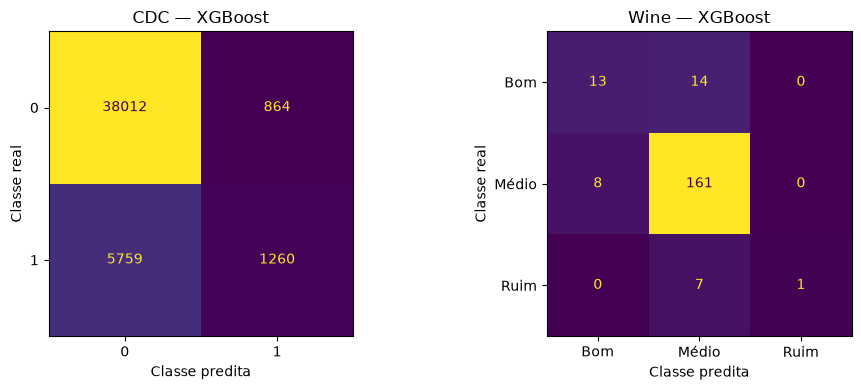

,modelo,dataset,conjunto,acurácia,precisão macro,revocação macro,F1 macro
0,Floresta aleatória,CDC,teste,0.8548,0.7391,0.5596,0.5702
1,Floresta aleatória,Wine,teste,0.8627,0.5276,0.4716,0.4889
2,XGBoost,CDC,teste,0.8557,0.7308,0.5786,0.5977
3,XGBoost,Wine,teste,0.8578,0.8346,0.5197,0.5604


,dataset,modelo,tempo de treino (s)
0,CDC,XGBoost,0.211
1,CDC,Floresta aleatória,16.870
2,Wine,XGBoost,0.036
3,Wine,Floresta aleatória,0.489


In [ ]:
resultados_xgboost = []
predicoes_xgboost = {}

for nome in ["CDC", "Wine"]:

    modelo = xgboosts[nome]
    X_teste = dados[nome][2]
    y_teste = dados[nome][3]
    codificador = codificadores_xgboost[nome]

    y_pred_codificado = modelo.predict(X_teste)
    y_pred_codificado = y_pred_codificado.astype(int)
    y_pred = codificador.inverse_transform(y_pred_codificado)
    precisao, revocacao, f1, suporte = precision_recall_fscore_support(
        y_teste, y_pred, average="macro", zero_division=0
    )
    resultados_xgboost.append({
        "modelo": "XGBoost",
        "dataset": nome,
        "conjunto": "teste",
        "acurácia": accuracy_score(y_teste, y_pred),
        "precisão macro": precisao,
        "revocação macro": revocacao,
        "F1 macro": f1,
    })
    predicoes_xgboost[nome] = y_pred

resultados_xgboost = pd.DataFrame(resultados_xgboost)
display(resultados_xgboost.round(4))
print()

fig, eixos = plt.subplots(1, 2, figsize=(10, 4), squeeze=False)

for coluna, nome in enumerate(["CDC", "Wine"]):
    eixo = eixos[0, coluna]
    y_teste = dados[nome][3]
    y_pred = predicoes_xgboost[nome]
    labels = codificadores_xgboost[nome].classes_
    ConfusionMatrixDisplay.from_predictions(
        y_teste, y_pred, labels=labels, ax=eixo, colorbar=False
    )
    eixo.set_title(f"{nome} — XGBoost")
    eixo.set_xlabel("Classe predita")
    eixo.set_ylabel("Classe real")

fig.tight_layout()
plt.show()

mascara_teste = resultados_floresta["conjunto"] == "teste"
resultados_floresta_teste = resultados_floresta[mascara_teste]
comparacao_final = pd.concat([
    resultados_floresta_teste, resultados_xgboost
], ignore_index=True)
display(comparacao_final.round(4))
print()

registros_tempo = []

for nome in ["CDC", "Wine"]:
    registros_tempo.append({
        "dataset": nome,
        "modelo": "Floresta aleatória",
        "tempo de treino (s)": tempos_floresta[nome],
    })
    registros_tempo.append({
        "dataset": nome,
        "modelo": "XGBoost",
        "tempo de treino (s)": tempos_xgboost[nome],
    })

comparacao_tempo = pd.DataFrame(registros_tempo)
comparacao_tempo = comparacao_tempo.sort_values(["dataset", "tempo de treino (s)"])
comparacao_tempo = comparacao_tempo.reset_index(drop=True)
display(comparacao_tempo.round(3))

### Discussão dos resultados

No CDC, a floresta teve acurácia de 0,8548 e F1 macro de 0,5702, enquanto o XGBoost teve acurácia de 0,8557 e F1 macro de 0,5977. As acurácias ficaram próximas, mas o XGBoost teve um F1 macro um pouquinho maior. O ajuste final da floresta levou 16,870 segundos, enquanto o do XGBoost levou 0,211 segundos. Nesta execução, o XGBoost teve F1 macro maior e levou menos tempo para treinar, ou seja, ganhou em tempo e em F1.

No Wine, a floresta teve acurácia de 0,8627 e F1 macro de 0,4889, já o XGBoost teve acurácia um pouco menor, de 0,8578, mas F1 macro maior, de 0,5604. O ajuste final levou 0,489 segundos na floresta e 0,036 segundos no XGBoost, diferença em segundos praticamente desprezível, mas mais de 10x mais rápido. Novamente, a vantagem do XGBoost apareceu principalmente no F1 macro, sem aumentar o tempo de treino.
